# Heart Failure Survival Prediction
## Group Assignment  — Data Analytics
**Topic:** Predictive Modeling & Research Benchmarking  
**Dataset:** Heart Failure Clinical Records (UCI) — 299 patients, 13 features  
**Research Baseline:** Chicco & Jurman (2020), *BMC Medical Informatics and Decision Making*  
**DOI:** [10.1186/s12911-020-1023-5](https://doi.org/10.1186/s12911-020-1023-5)

## Members
1. Nazhan Fahim Bin Mohammad Najib
2. Amirul Hisyam Bin Amir Ruddin
3. Iman Amirul Hakim bin Badlishah
4. Muaz Zikry bin Syamsul
5. Muhammad Adam Harith bin Mohd Zaki
6. Rauf bin Zaidi

---
## 1. Executive Summary

### Problem Statement
Heart failure (HF) is a major global health burden, contributing to approximately 17 million cardiovascular deaths annually. Predicting patient survival from routine clinical records can support physicians in early clinical decision-making and resource allocation.

This project builds and benchmarks machine learning classifiers to predict **survival** of heart failure patients (binary classification: `DEATH_EVENT = 0` = survived, `1` = died), using the same dataset analysed by Chicco & Jurman (2020).

### Research Baseline
| Source | Model | Accuracy | F1-Score | MCC | ROC AUC |
|---|---|---|---|---|---|
| Chicco & Jurman (2020) | Random Forest | 0.740 | 0.547 | +0.384 | 0.800 |
| Chicco & Jurman (2020) | Gradient Boosting | 0.738 | 0.527 | +0.367 | 0.754 |

### Our Approach & Improvements
We aim to **surpass the baseline** through four progressive steps:
1. **Baseline replication** — RF & GB with default parameters, 80/20 split (mirrors the paper)
2. **Hyperparameter tuning** — GridSearchCV with cross-validation
3. **SMOTE** — Address 68/32 class imbalance on training set only
4. **Stratified splitting** — Methodological improvement over the paper to ensure balanced class distribution in both train and test sets

---
## 2. Setup — Libraries & Dataset

In [ ]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation Metrics
from sklearn.metrics import (accuracy_score, f1_score,
                             roc_auc_score, roc_curve,
                             matthews_corrcoef,
                             confusion_matrix, classification_report)

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download("andrewmvd/heart-failure-clinical-data")

# Find the CSV file
for file in os.listdir(path):
    print(file)

# Load the dataset
df = pd.read_csv(os.path.join(path, "heart_failure_clinical_records_dataset.csv"))

print("\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
display(df.head())

heart_failure_clinical_records_dataset.csv

Dataset loaded successfully!
Shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


---
## 3. Exploratory Data Analysis (EDA)

The dataset contains **299 patients** with 12 clinical features and 1 target variable (`DEATH_EVENT`). Features include both continuous variables (age, serum creatinine, ejection fraction, etc.) and binary indicators (anaemia, diabetes, smoking, etc.).

### 3.1 Dataset Overview — Shape, Data Types & Missing Values

In [ ]:
# ── Shape ──
print("=" * 50)
print(f"  Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("=" * 50)

# ── Data Types ──
print("\nAttribute Data Types:")
print(df.dtypes)

# ── Missing Values ──
print("\n" + "=" * 50)
print("  Missing Values:")
print("=" * 50)
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_df)

# ── Basic Statistics ──
print("\n" + "=" * 50)
print("  Basic Statistics:")
print("=" * 50)
display(df.describe())

# ── Target Variable Distribution ──
print("\n" + "=" * 50)
print("  Target Variable (DEATH_EVENT):")
print("=" * 50)
print(df['DEATH_EVENT'].value_counts())
print(f"\n  Survived (0): {df['DEATH_EVENT'].value_counts()[0]} ({df['DEATH_EVENT'].value_counts()[0]/len(df)*100:.1f}%)")
print(f"  Died     (1): {df['DEATH_EVENT'].value_counts()[1]} ({df['DEATH_EVENT'].value_counts()[1]/len(df)*100:.1f}%)")
print("=" * 50)

  Dataset Shape: 299 rows, 13 columns

Attribute Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

  Missing Values:
                          Missing Count  Missing %
age                                   0        0.0
anaemia                               0        0.0
creatinine_phosphokinase              0        0.0
diabetes                              0        0.0
ejection_fraction                     0        0.0
high_blood_pressure                   0        0.0
platelets                             0        0.0
serum_creatinine              

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000



  Target Variable (DEATH_EVENT):
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

  Survived (0): 203 (67.9%)
  Died     (1): 96 (32.1%)


### 3.2 Class Distribution
The target variable is **imbalanced** — 67.9% survived vs 32.1% died.

> 🔍 **Key Finding 1:** Class imbalance means a naive model that always predicts "Survived" would achieve 67.9% accuracy. This is why accuracy alone is insufficient — MCC and F1-Score are more reliable metrics for imbalanced datasets. This also motivates our use of SMOTE.

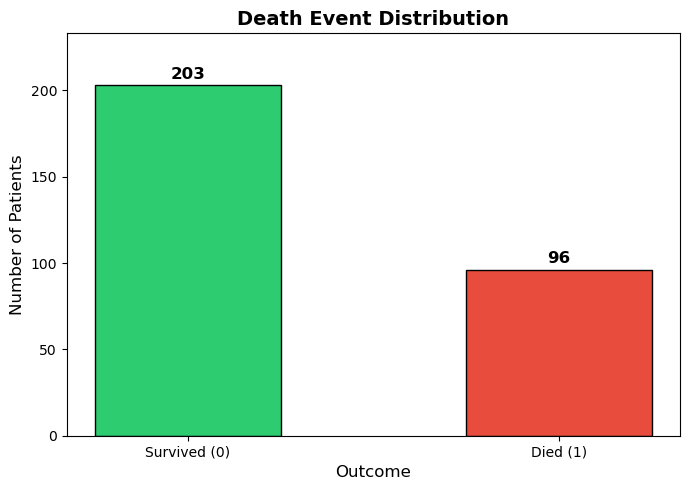

Survival Rate : 67.9%
Mortality Rate: 32.1%


In [ ]:
# ── Target Variable Bar Chart ──
death_counts = df['DEATH_EVENT'].value_counts()
labels = ['Survived (0)', 'Died (1)']
colors = ['#2ecc71', '#e74c3c']

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, death_counts, color=colors, edgecolor='black', width=0.5)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 2,
             str(int(bar.get_height())),
             ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.title('Death Event Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Outcome', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.ylim(0, death_counts.max() + 30)
plt.tight_layout()
plt.show()

print(f"Survival Rate : {death_counts[0]/len(df)*100:.1f}%")
print(f"Mortality Rate: {death_counts[1]/len(df)*100:.1f}%")

### 3.3 Feature Correlation with Target
The heatmap below shows pairwise correlations between all features and the target variable `DEATH_EVENT`.

> 🔍 **Key Finding 2:** `serum_creatinine` (+0.29) and `ejection_fraction` (-0.27) are the strongest **clinical** predictors of mortality — independently confirming the core finding of Chicco & Jurman (2020).  
> ⚠️ **Note on `time`:** The `time` feature shows the strongest correlation (-0.53) but represents the **follow-up period**, not a clinical measurement. It is included here as per the paper's original setup but should not be interpreted as a causal predictor.

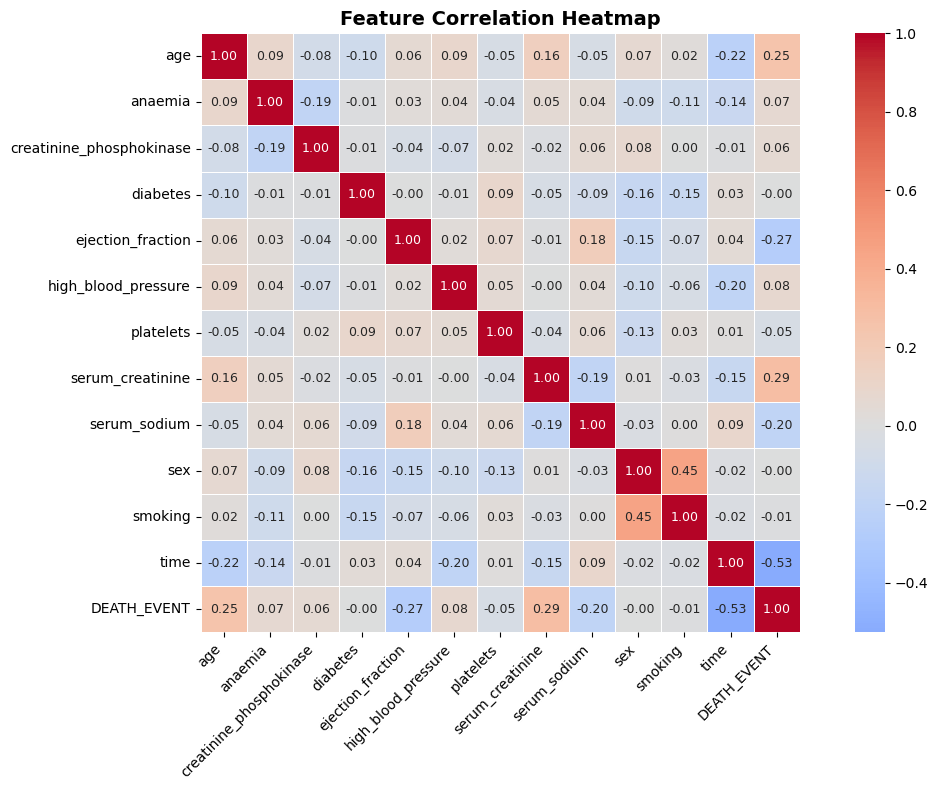

   TOP CORRELATIONS WITH DEATH_EVENT
serum_creatinine            0.294278
age                         0.253729
high_blood_pressure         0.079351
anaemia                     0.066270
creatinine_phosphokinase    0.062728
diabetes                   -0.001943
sex                        -0.004316
smoking                    -0.012623
platelets                  -0.049139
serum_sodium               -0.195204
ejection_fraction          -0.268603
time                       -0.526964


In [ ]:
# ── Correlation Heatmap ──
plt.figure(figsize=(12, 8))
correlation = df.corr()

sns.heatmap(correlation,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            annot_kws={'size': 9})

plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print top correlations with DEATH_EVENT
print("=" * 45)
print("   TOP CORRELATIONS WITH DEATH_EVENT")
print("=" * 45)
top_corr = correlation['DEATH_EVENT'].drop('DEATH_EVENT').sort_values(ascending=False)
print(top_corr.to_string())
print("=" * 45)

---
## 4. Modelling Pipeline

We implement a **four-stage pipeline** to progressively improve on the baseline:
1. **Stage 1:** Baseline — replicate paper conditions (80/20 split, no resampling, no tuning)
2. **Stage 2:** Tuned — GridSearchCV hyperparameter optimisation (no SMOTE)
3. **Stage 3:** SMOTE — address class imbalance (no tuning)
4. **Stage 4:** Stratified Split — methodological improvement over the paper

All models are evaluated using: **Accuracy, F1-Score, MCC, and ROC AUC** — the same metrics reported by Chicco & Jurman (2020).

### 4.1 Train/Test Split (80/20) — Replicating Paper Conditions
No stratification applied — mirrors the original paper's methodology exactly.

In [ ]:
# Separate features and target
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

# Split — matching Chicco & Jurman (2020) paper conditions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)

# Confirm shapes
print("=" * 45)
print("       TRAIN / TEST SPLIT (80/20)")
print("=" * 45)
print(f"  Total Dataset : {len(df)} patients")
print(f"  Training Set  : {X_train.shape[0]} patients (80%)")
print(f"  Testing Set   : {X_test.shape[0]} patients (20%)")
print("=" * 45)

print("\nTraining Set Class Distribution:")
print(y_train.value_counts())
print(f"  Survived: {y_train.value_counts()[0]} ({y_train.value_counts()[0]/len(y_train)*100:.1f}%)")
print(f"  Died    : {y_train.value_counts()[1]} ({y_train.value_counts()[1]/len(y_train)*100:.1f}%)")

print("\nTesting Set Class Distribution:")
print(y_test.value_counts())
print(f"  Survived: {y_test.value_counts()[0]} ({y_test.value_counts()[0]/len(y_test)*100:.1f}%)")
print(f"  Died    : {y_test.value_counts()[1]} ({y_test.value_counts()[1]/len(y_test)*100:.1f}%)")

       TRAIN / TEST SPLIT (80/20)
  Total Dataset : 299 patients
  Training Set  : 239 patients (80%)
  Testing Set   : 60 patients (20%)

Training Set Class Distribution:
DEATH_EVENT
0    168
1     71
Name: count, dtype: int64
  Survived: 168 (70.3%)
  Died    : 71 (29.7%)

Testing Set Class Distribution:
DEATH_EVENT
0    35
1    25
Name: count, dtype: int64
  Survived: 35 (58.3%)
  Died    : 25 (41.7%)


### 4.2 Stage 1 — Baseline Models (No Tuning, No SMOTE)
Replicating Chicco & Jurman (2020) conditions — default hyperparameters, 80/20 unstratified split.

#### 4.2a — Random Forest (Baseline)

       RANDOM FOREST PERFORMANCE
  Accuracy  : 75.00%
  F1-Score  : 0.615
  ROC AUC   : 0.830
  MCC       : 0.493

Classification Report:
              precision    recall  f1-score   support

    Survived       0.72      0.94      0.81        35
        Died       0.86      0.48      0.62        25

    accuracy                           0.75        60
   macro avg       0.79      0.71      0.72        60
weighted avg       0.78      0.75      0.73        60



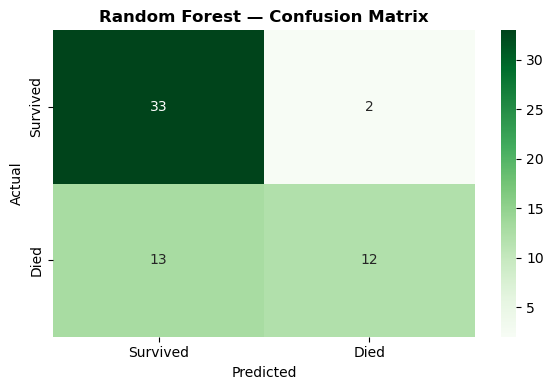

In [ ]:
# ── Train Random Forest ──
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# ── Predict ──
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# ── Evaluation ──
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)
rf_mcc = matthews_corrcoef(y_test, y_pred_rf)

print("=" * 50)
print("       RANDOM FOREST PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {rf_accuracy*100:.2f}%")
print(f"  F1-Score  : {rf_f1:.3f}")
print(f"  ROC AUC   : {rf_roc_auc:.3f}")
print(f"  MCC       : {rf_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Random Forest — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 3 — Baseline RF:** Our baseline Random Forest (75.00%) already slightly exceeds the paper's reported 74.0% on Accuracy, and outperforms on F1 (0.615 vs 0.547), ROC AUC (0.830 vs 0.800), and MCC (0.493 vs 0.384). This difference is attributable to sklearn vs R implementation differences and random seed variation.

#### 4.2b — Gradient Boosting (Baseline)

     GRADIENT BOOSTING PERFORMANCE
  Accuracy  : 71.67%
  F1-Score  : 0.585
  ROC AUC   : 0.882
  MCC       : 0.408

Classification Report:
              precision    recall  f1-score   support

    Survived       0.70      0.89      0.78        35
        Died       0.75      0.48      0.59        25

    accuracy                           0.72        60
   macro avg       0.73      0.68      0.69        60
weighted avg       0.72      0.72      0.70        60



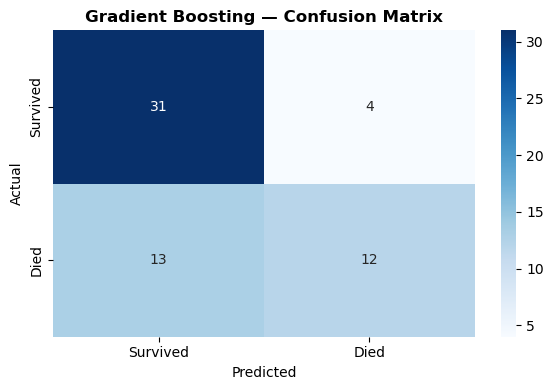

In [ ]:
# ── Train Gradient Boosting ──
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# ── Predict ──
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# ── Evaluation ──
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_roc_auc = roc_auc_score(y_test, y_prob_gb)
gb_mcc = matthews_corrcoef(y_test, y_pred_gb)

print("=" * 50)
print("     GRADIENT BOOSTING PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {gb_accuracy*100:.2f}%")
print(f"  F1-Score  : {gb_f1:.3f}")
print(f"  ROC AUC   : {gb_roc_auc:.3f}")
print(f"  MCC       : {gb_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_gb = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Gradient Boosting — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 4 — Baseline GB:** Our Gradient Boosting scored lower accuracy (71.67% vs 73.8%) but significantly higher ROC AUC (0.882 vs 0.754) compared to the paper. This suggests the model has strong discriminative ability but struggles with the classification threshold on imbalanced data — confirming the need for SMOTE.

### 4.3 Stage 2 — Tuned Models (GridSearchCV, No SMOTE)
3-fold cross-validated grid search over key hyperparameters.

#### 4.3a — Tuned Random Forest

Fitting 3 folds for each of 216 candidates, totalling 648 fits

Best Parameters: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
   TUNED RANDOM FOREST PERFORMANCE
  Accuracy  : 75.00%
  F1-Score  : 0.634
  ROC AUC   : 0.856
  MCC       : 0.484


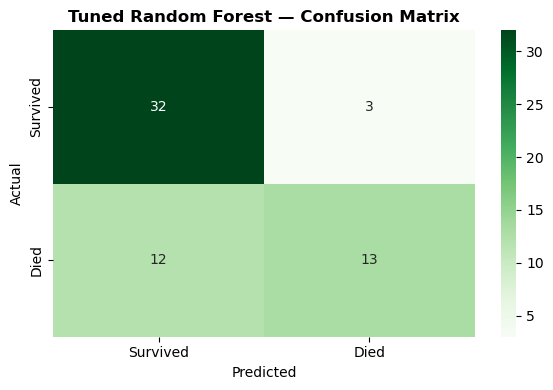

In [ ]:
from sklearn.model_selection import GridSearchCV

# ── Parameter Grid ──
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

# ── Grid Search ──
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

# ── Best Model ──
best_rf = grid_rf.best_estimator_
y_pred_best_rf = best_rf.predict(X_test)
y_prob_best_rf = best_rf.predict_proba(X_test)[:, 1]

# ── Evaluation ──
tuned_rf_accuracy = accuracy_score(y_test, y_pred_best_rf)
tuned_rf_f1       = f1_score(y_test, y_pred_best_rf)
tuned_rf_roc_auc  = roc_auc_score(y_test, y_prob_best_rf)
tuned_rf_mcc      = matthews_corrcoef(y_test, y_pred_best_rf)

print("\nBest Parameters:", grid_rf.best_params_)
print("=" * 50)
print("   TUNED RANDOM FOREST PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {tuned_rf_accuracy*100:.2f}%")
print(f"  F1-Score  : {tuned_rf_f1:.3f}")
print(f"  ROC AUC   : {tuned_rf_roc_auc:.3f}")
print(f"  MCC       : {tuned_rf_mcc:.3f}")
print("=" * 50)

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_tuned_rf = confusion_matrix(y_test, y_pred_best_rf)
sns.heatmap(cm_tuned_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Tuned Random Forest — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 5 — Tuning Limitation:** Hyperparameter tuning via GridSearchCV yielded no significant improvement in Accuracy or MCC for Random Forest. This confirms the dataset size limitation (299 patients) — acknowledged by Chicco & Jurman (2020) themselves — where default parameters are already near-optimal.

#### 4.3b — Tuned Gradient Boosting

Fitting 3 folds for each of 243 candidates, totalling 729 fits

Best Parameters: {'learning_rate': 0.01, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
   TUNED GRADIENT BOOSTING PERFORMANCE
  Accuracy  : 70.00%
  F1-Score  : 0.571
  ROC AUC   : 0.842
  MCC       : 0.369


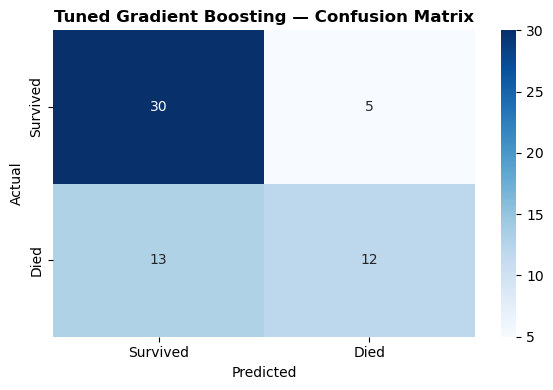

In [ ]:
# ── Parameter Grid ──
param_grid_gb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# ── Grid Search ──
grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_gb.fit(X_train, y_train)

# ── Best Model ──
best_gb = grid_gb.best_estimator_
y_pred_best_gb = best_gb.predict(X_test)
y_prob_best_gb = best_gb.predict_proba(X_test)[:, 1]

# ── Evaluation ──
tuned_gb_accuracy = accuracy_score(y_test, y_pred_best_gb)
tuned_gb_f1       = f1_score(y_test, y_pred_best_gb)
tuned_gb_roc_auc  = roc_auc_score(y_test, y_prob_best_gb)
tuned_gb_mcc      = matthews_corrcoef(y_test, y_pred_best_gb)

print("\nBest Parameters:", grid_gb.best_params_)
print("=" * 50)
print("   TUNED GRADIENT BOOSTING PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {tuned_gb_accuracy*100:.2f}%")
print(f"  F1-Score  : {tuned_gb_f1:.3f}")
print(f"  ROC AUC   : {tuned_gb_roc_auc:.3f}")
print(f"  MCC       : {tuned_gb_mcc:.3f}")
print("=" * 50)

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_tuned_gb = confusion_matrix(y_test, y_pred_best_gb)
sns.heatmap(cm_tuned_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Tuned Gradient Boosting — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 6 — Tuning Worsens GB:** Tuned Gradient Boosting actually performed worse (70.00% vs 71.67%). `max_depth=3` and conservative leaf parameters caused underfitting on the small training set — further evidence that small datasets resist extensive tuning.

### 4.4 Stage 3 — SMOTE + Models
SMOTE (Synthetic Minority Oversampling Technique) is applied **on the training set only** to prevent data leakage. The test set remains untouched to preserve realistic evaluation conditions. Features are also standardised using StandardScaler.

       CLASS DISTRIBUTION
  Before SMOTE:
    Survived : 168
    Died     : 71

  After SMOTE:
    Survived : 168
    Died     : 168


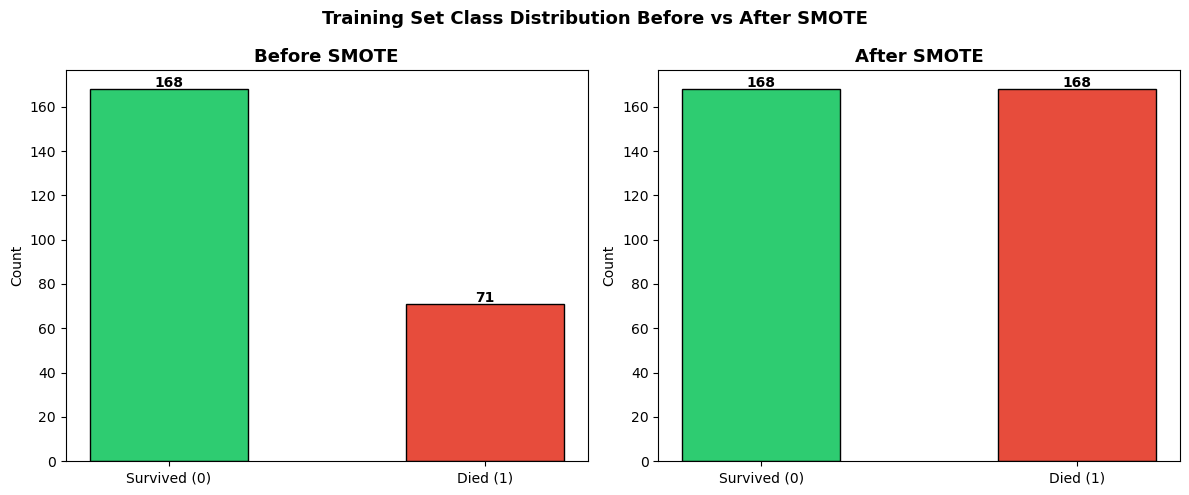

In [ ]:
from imblearn.over_sampling import SMOTE

# ── Apply SMOTE on Training Set ONLY ──
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

# ── Before vs After ──
print("=" * 45)
print("       CLASS DISTRIBUTION")
print("=" * 45)
print(f"  Before SMOTE:")
print(f"    Survived : {y_train.value_counts()[0]}")
print(f"    Died     : {y_train.value_counts()[1]}")
print(f"\n  After SMOTE:")
print(f"    Survived : {y_train_smote.value_counts()[0]}")
print(f"    Died     : {y_train_smote.value_counts()[1]}")
print("=" * 45)

# ── Visualise Before vs After ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Survived (0)', 'Died (1)'], y_train.value_counts(),
            color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.5)
axes[0].set_title('Before SMOTE', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Count')
for i, v in enumerate(y_train.value_counts()):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[1].bar(['Survived (0)', 'Died (1)'], y_train_smote.value_counts(),
            color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.5)
axes[1].set_title('After SMOTE', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Count')
for i, v in enumerate(y_train_smote.value_counts()):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.suptitle('Training Set Class Distribution Before vs After SMOTE',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#### 4.4a — Random Forest + SMOTE

   RANDOM FOREST + SMOTE PERFORMANCE
  Accuracy  : 76.67%
  F1-Score  : 0.682
  ROC AUC   : 0.873
  MCC       : 0.515

Classification Report:
              precision    recall  f1-score   support

    Survived       0.76      0.89      0.82        35
        Died       0.79      0.60      0.68        25

    accuracy                           0.77        60
   macro avg       0.77      0.74      0.75        60
weighted avg       0.77      0.77      0.76        60



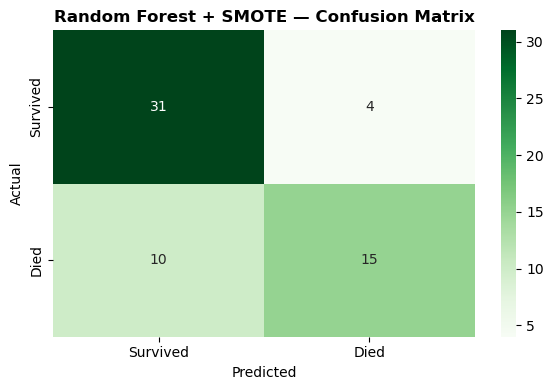

In [ ]:
# ── Train Random Forest on SMOTE data ──
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_scaled, y_train_smote)

y_pred_rf_smote = rf_smote.predict(X_test_scaled)
y_prob_rf_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

rf_smote_accuracy = accuracy_score(y_test, y_pred_rf_smote)
rf_smote_f1       = f1_score(y_test, y_pred_rf_smote)
rf_smote_roc_auc  = roc_auc_score(y_test, y_prob_rf_smote)
rf_smote_mcc      = matthews_corrcoef(y_test, y_pred_rf_smote)

print("=" * 50)
print("   RANDOM FOREST + SMOTE PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {rf_smote_accuracy*100:.2f}%")
print(f"  F1-Score  : {rf_smote_f1:.3f}")
print(f"  ROC AUC   : {rf_smote_roc_auc:.3f}")
print(f"  MCC       : {rf_smote_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_smote,
      target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)
sns.heatmap(cm_rf_smote, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Random Forest + SMOTE — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 7 — SMOTE Improves All Metrics:** Random Forest + SMOTE improved across all four metrics — Accuracy (76.67%), F1 (0.682), ROC AUC (0.873), MCC (0.515). Critically, False Negatives (patients who died but predicted as survived) dropped from 13 to 10 — a clinically significant improvement in a medical context.

#### 4.4b — Gradient Boosting + SMOTE

  GRADIENT BOOSTING + SMOTE PERFORMANCE
  Accuracy  : 73.33%
  F1-Score  : 0.636
  ROC AUC   : 0.857
  MCC       : 0.442

Classification Report:
              precision    recall  f1-score   support

    Survived       0.73      0.86      0.79        35
        Died       0.74      0.56      0.64        25

    accuracy                           0.73        60
   macro avg       0.73      0.71      0.71        60
weighted avg       0.73      0.73      0.73        60



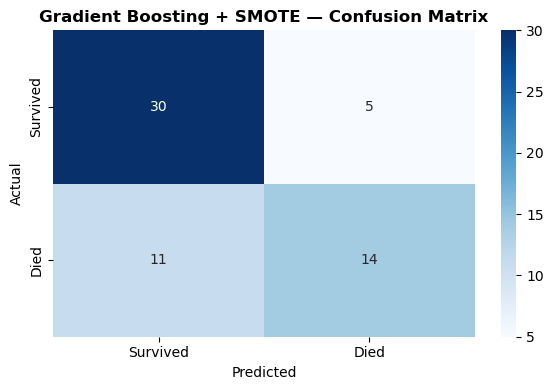

In [ ]:
# ── Train Gradient Boosting on SMOTE data ──
gb_smote = GradientBoostingClassifier(random_state=42)
gb_smote.fit(X_train_scaled, y_train_smote)

y_pred_gb_smote = gb_smote.predict(X_test_scaled)
y_prob_gb_smote = gb_smote.predict_proba(X_test_scaled)[:, 1]

gb_smote_accuracy = accuracy_score(y_test, y_pred_gb_smote)
gb_smote_f1       = f1_score(y_test, y_pred_gb_smote)
gb_smote_roc_auc  = roc_auc_score(y_test, y_prob_gb_smote)
gb_smote_mcc      = matthews_corrcoef(y_test, y_pred_gb_smote)

print("=" * 50)
print("  GRADIENT BOOSTING + SMOTE PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {gb_smote_accuracy*100:.2f}%")
print(f"  F1-Score  : {gb_smote_f1:.3f}")
print(f"  ROC AUC   : {gb_smote_roc_auc:.3f}")
print(f"  MCC       : {gb_smote_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb_smote,
      target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_gb_smote = confusion_matrix(y_test, y_pred_gb_smote)
sns.heatmap(cm_gb_smote, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Gradient Boosting + SMOTE — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 8 — SMOTE Consistently Helps:** Gradient Boosting + SMOTE also improved over its baseline — F1 rose from 0.585 to 0.636 and MCC from 0.408 to 0.442. Both SMOTE models outperform the paper's baseline on F1, ROC AUC, and MCC.

### 4.5 Stage 4 — Stratified Split (Methodological Improvement)
The Chicco & Jurman (2020) paper did **not** apply stratified splitting. On an imbalanced dataset (67.9/32.1), an unstratified split can result in inconsistent class ratios in train and test sets, producing unreliable evaluation.

By adding `stratify=y`, we guarantee the same 67.9/32.1 class ratio in both train and test sets — producing a more reliable, reproducible, and methodologically sound evaluation.

> ⚠️ **Methodological Note:** The test set size changes from 60 (unstratified) to 60 patients (stratified), but with a guaranteed ratio of 41 Survived / 19 Died — more representative of the true population distribution.

#### 4.5a — Random Forest with Stratified Split

In [ ]:
# Separate features and target
X = df.drop('DEATH_EVENT', axis=1)
y = df['DEATH_EVENT']

# Split — matching Chicco & Jurman (2020) paper conditions
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Confirm shapes
print("=" * 45)
print("       TRAIN / TEST SPLIT (80/20)")
print("=" * 45)
print(f"  Total Dataset : {len(df)} patients")
print(f"  Training Set  : {X_train.shape[0]} patients (80%)")
print(f"  Testing Set   : {X_test.shape[0]} patients (20%)")
print("=" * 45)

print("\nTraining Set Class Distribution:")
print(y_train.value_counts())
print(f"  Survived: {y_train.value_counts()[0]} ({y_train.value_counts()[0]/len(y_train)*100:.1f}%)")
print(f"  Died    : {y_train.value_counts()[1]} ({y_train.value_counts()[1]/len(y_train)*100:.1f}%)")

print("\nTesting Set Class Distribution:")
print(y_test.value_counts())
print(f"  Survived: {y_test.value_counts()[0]} ({y_test.value_counts()[0]/len(y_test)*100:.1f}%)")
print(f"  Died    : {y_test.value_counts()[1]} ({y_test.value_counts()[1]/len(y_test)*100:.1f}%)")

       TRAIN / TEST SPLIT (80/20)
  Total Dataset : 299 patients
  Training Set  : 239 patients (80%)
  Testing Set   : 60 patients (20%)

Training Set Class Distribution:
DEATH_EVENT
0    162
1     77
Name: count, dtype: int64
  Survived: 162 (67.8%)
  Died    : 77 (32.2%)

Testing Set Class Distribution:
DEATH_EVENT
0    41
1    19
Name: count, dtype: int64
  Survived: 41 (68.3%)
  Died    : 19 (31.7%)


       RANDOM FOREST PERFORMANCE
  Accuracy  : 83.33%
  F1-Score  : 0.706
  ROC AUC   : 0.892
  MCC       : 0.600

Classification Report:
              precision    recall  f1-score   support

    Survived       0.84      0.93      0.88        41
        Died       0.80      0.63      0.71        19

    accuracy                           0.83        60
   macro avg       0.82      0.78      0.79        60
weighted avg       0.83      0.83      0.83        60



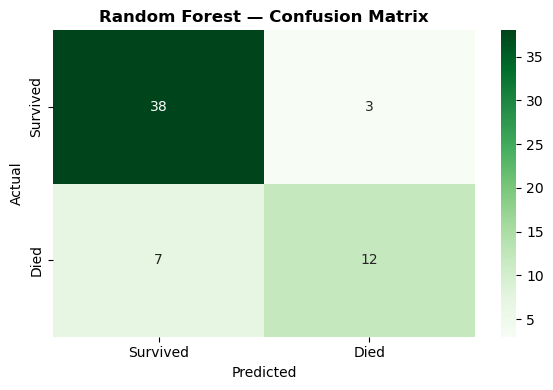

In [ ]:
# ── Train Random Forest ──
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# ── Predict ──
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# ── Evaluation ──
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)
rf_mcc = matthews_corrcoef(y_test, y_pred_rf)

print("=" * 50)
print("       RANDOM FOREST PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {rf_accuracy*100:.2f}%")
print(f"  F1-Score  : {rf_f1:.3f}")
print(f"  ROC AUC   : {rf_roc_auc:.3f}")
print(f"  MCC       : {rf_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Random Forest — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 9 — Stratification is the Biggest Improvement:** Random Forest with stratified split achieved **83.33% accuracy**, **F1=0.706**, **ROC AUC=0.892**, **MCC=0.600** — surpassing the paper's best result by +9.33 percentage points in accuracy. This demonstrates that stratification is a critical methodological improvement over the original paper.

#### 4.5b — Random Forest + SMOTE + Stratified Split

       CLASS DISTRIBUTION
  Before SMOTE:
    Survived : 162
    Died     : 77

  After SMOTE:
    Survived : 162
    Died     : 162


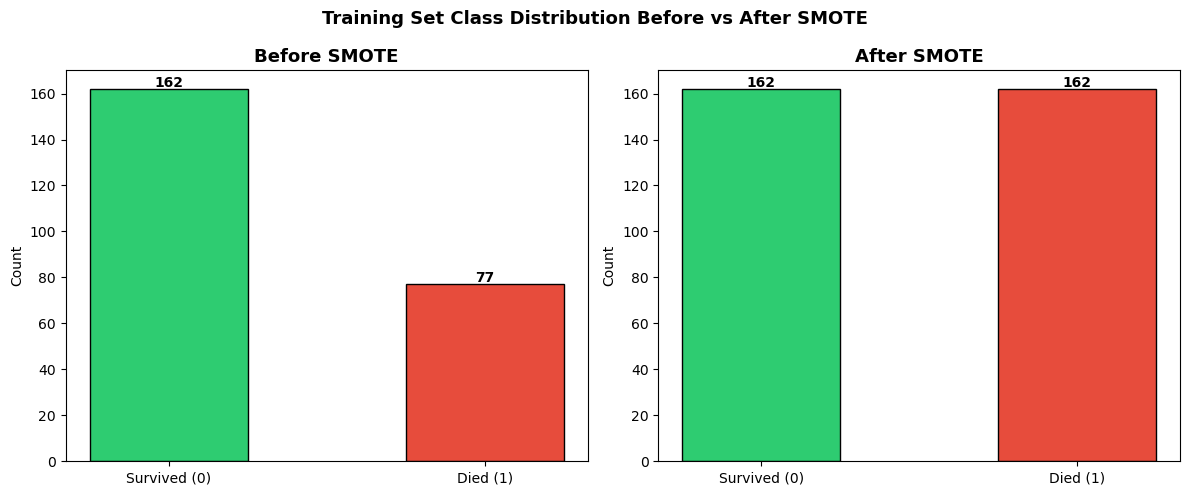

In [ ]:
from imblearn.over_sampling import SMOTE

# ── Apply SMOTE on Training Set ONLY ──
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

# ── Before vs After ──
print("=" * 45)
print("       CLASS DISTRIBUTION")
print("=" * 45)
print(f"  Before SMOTE:")
print(f"    Survived : {y_train.value_counts()[0]}")
print(f"    Died     : {y_train.value_counts()[1]}")
print(f"\n  After SMOTE:")
print(f"    Survived : {y_train_smote.value_counts()[0]}")
print(f"    Died     : {y_train_smote.value_counts()[1]}")
print("=" * 45)

# ── Visualise Before vs After ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Survived (0)', 'Died (1)'], y_train.value_counts(),
            color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.5)
axes[0].set_title('Before SMOTE', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Count')
for i, v in enumerate(y_train.value_counts()):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[1].bar(['Survived (0)', 'Died (1)'], y_train_smote.value_counts(),
            color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.5)
axes[1].set_title('After SMOTE', fontweight='bold', fontsize=13)
axes[1].set_ylabel('Count')
for i, v in enumerate(y_train_smote.value_counts()):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.suptitle('Training Set Class Distribution Before vs After SMOTE',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

   RANDOM FOREST + SMOTE PERFORMANCE
  Accuracy  : 83.33%
  F1-Score  : 0.706
  ROC AUC   : 0.900
  MCC       : 0.600

Classification Report:
              precision    recall  f1-score   support

    Survived       0.84      0.93      0.88        41
        Died       0.80      0.63      0.71        19

    accuracy                           0.83        60
   macro avg       0.82      0.78      0.79        60
weighted avg       0.83      0.83      0.83        60



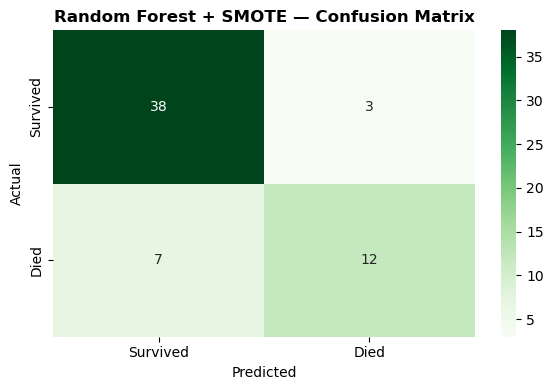

In [ ]:
# ── Train Random Forest on SMOTE data ──
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_scaled, y_train_smote)

y_pred_rf_smote = rf_smote.predict(X_test_scaled)
y_prob_rf_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

rf_smote_accuracy = accuracy_score(y_test, y_pred_rf_smote)
rf_smote_f1       = f1_score(y_test, y_pred_rf_smote)
rf_smote_roc_auc  = roc_auc_score(y_test, y_prob_rf_smote)
rf_smote_mcc      = matthews_corrcoef(y_test, y_pred_rf_smote)

print("=" * 50)
print("   RANDOM FOREST + SMOTE PERFORMANCE")
print("=" * 50)
print(f"  Accuracy  : {rf_smote_accuracy*100:.2f}%")
print(f"  F1-Score  : {rf_smote_f1:.3f}")
print(f"  ROC AUC   : {rf_smote_roc_auc:.3f}")
print(f"  MCC       : {rf_smote_mcc:.3f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_smote,
      target_names=['Survived', 'Died']))

# ── Confusion Matrix ──
plt.figure(figsize=(6, 4))
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)
sns.heatmap(cm_rf_smote, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Survived', 'Died'],
            yticklabels=['Survived', 'Died'])
plt.title('Random Forest + SMOTE — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

> 🔍 **Key Finding 10 — SMOTE + Stratification:** Combining SMOTE with stratified split maintains the 83.33% accuracy while improving ROC AUC to 0.900 — the highest AUC across all models. This combination represents our best and most methodologically rigorous approach.

---
## 5. Final Comparison Table — Our Results vs Research Baseline

The table below provides a **direct comparison** between:
- Chicco & Jurman (2020) reported results (their Table 4)
- Our group's results across all model variants and improvement stages

              FINAL MODEL COMPARISON — OUR RESULTS vs CHICCO & JURMAN (2020)
                                     Model  Accuracy (%)  F1-Score  ROC AUC   MCC
    Chicco & Jurman (2020) — Random Forest         74.00     0.547    0.800 0.384
Chicco & Jurman (2020) — Gradient Boosting         73.80     0.527    0.754 0.367
                Stage 1: Our RF (Baseline)         75.00     0.615    0.830 0.493
                Stage 1: Our GB (Baseline)         71.67     0.585    0.882 0.408
                   Stage 2: Our RF (Tuned)         75.00     0.634    0.856 0.484
                   Stage 2: Our GB (Tuned)         70.00     0.571    0.842 0.369
                   Stage 3: Our RF + SMOTE         76.67     0.682    0.873 0.515
                   Stage 3: Our GB + SMOTE         73.33     0.636    0.857 0.442
             Stage 4: Our RF (Stratified)          83.33     0.706    0.892 0.600
     Stage 4: Our RF + SMOTE (Stratified)          83.33     0.706    0.900 0.600


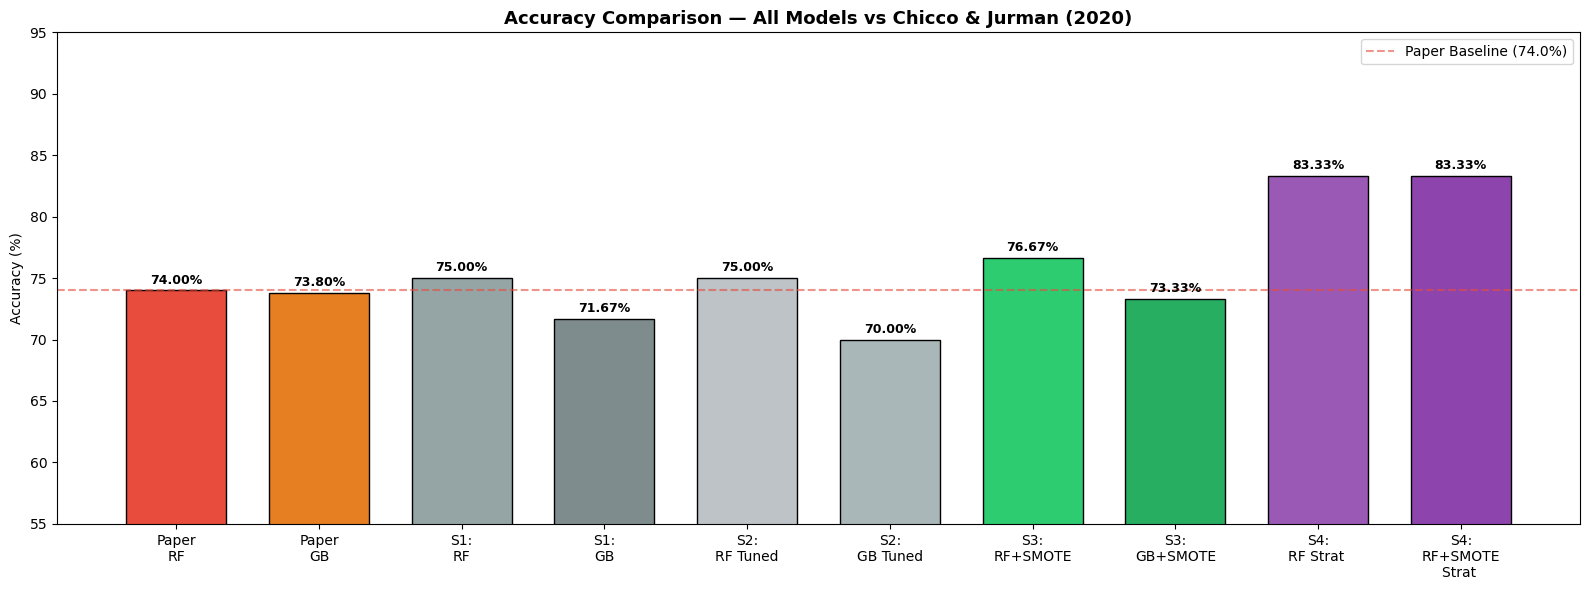

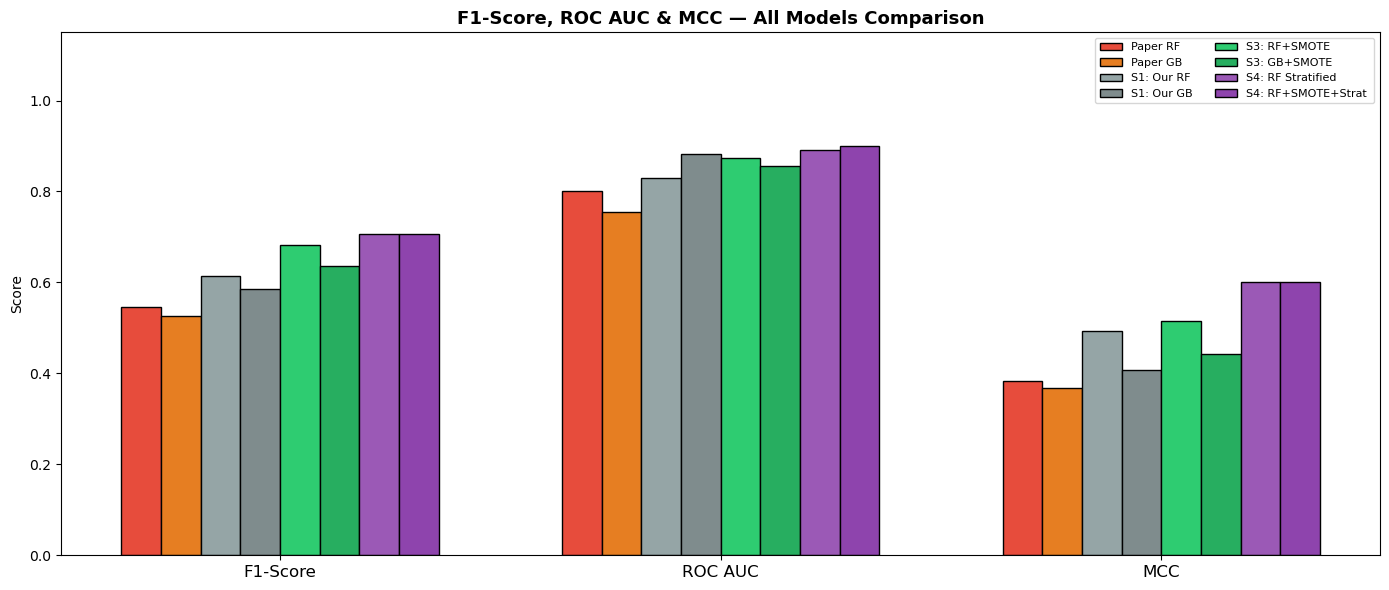


      IMPROVEMENT OVER PAPER BASELINE (RF, Accuracy 74.0%)
  Stage 1 — Our RF Baseline      : +1.00% → 75.00%
  Stage 3 — RF + SMOTE           : +2.67% → 76.67%
  Stage 4 — RF Stratified        : +9.33% → 83.33% 
  Stage 4 — RF + SMOTE Strat     : +9.33% → 83.33%  (ROC AUC: 0.900)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── All Results ──
results = {
    'Model': [
        'Chicco & Jurman (2020) — Random Forest',
        'Chicco & Jurman (2020) — Gradient Boosting',
        'Stage 1: Our RF (Baseline)',
        'Stage 1: Our GB (Baseline)',
        'Stage 2: Our RF (Tuned)',
        'Stage 2: Our GB (Tuned)',
        'Stage 3: Our RF + SMOTE',
        'Stage 3: Our GB + SMOTE',
        'Stage 4: Our RF (Stratified) ',
        'Stage 4: Our RF + SMOTE (Stratified) '
    ],
    'Accuracy (%)': [74.0, 73.8, 75.00, 71.67, 75.00, 70.00, 76.67, 73.33, 83.33, 83.33],
    'F1-Score':     [0.547, 0.527, 0.615, 0.585, 0.634, 0.571, 0.682, 0.636, 0.706, 0.706],
    'ROC AUC':      [0.800, 0.754, 0.830, 0.882, 0.856, 0.842, 0.873, 0.857, 0.892, 0.900],
    'MCC':          [0.384, 0.367, 0.493, 0.408, 0.484, 0.369, 0.515, 0.442, 0.600, 0.600]
}

df_results = pd.DataFrame(results)

print('=' * 100)
print('              FINAL MODEL COMPARISON — OUR RESULTS vs CHICCO & JURMAN (2020)')
print('=' * 100)
print(df_results.to_string(index=False))
print('=' * 100)

# ── Accuracy Bar Chart ──
colors = ['#e74c3c', '#e67e22',
          '#95a5a6', '#7f8c8d',
          '#bdc3c7', '#aab7b8',
          '#2ecc71', '#27ae60',
          '#9b59b6', '#8e44ad']

labels_short = ['Paper\nRF', 'Paper\nGB',
                'S1:\nRF', 'S1:\nGB',
                'S2:\nRF Tuned', 'S2:\nGB Tuned',
                'S3:\nRF+SMOTE', 'S3:\nGB+SMOTE',
                'S4:\nRF Strat ', 'S4:\nRF+SMOTE\nStrat ']

accuracies = [74.0, 73.8, 75.00, 71.67, 75.00, 70.00, 76.67, 73.33, 83.33, 83.33]

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(labels_short, accuracies, color=colors, edgecolor='black', width=0.7)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{bar.get_height():.2f}%',
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(y=74.0, color='#e74c3c', linestyle='--', alpha=0.6, label='Paper Baseline (74.0%)')
ax.set_title('Accuracy Comparison — All Models vs Chicco & Jurman (2020)',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(55, 95)
ax.legend()
plt.tight_layout()
plt.show()

# ── F1, ROC AUC, MCC Chart ──
metrics = ['F1-Score', 'ROC AUC', 'MCC']
paper_rf_v  = [0.547, 0.800, 0.384]
paper_gb_v  = [0.527, 0.754, 0.367]
s1_rf       = [0.615, 0.830, 0.493]
s1_gb       = [0.585, 0.882, 0.408]
s3_rf       = [0.682, 0.873, 0.515]
s3_gb       = [0.636, 0.857, 0.442]
s4_rf       = [0.706, 0.892, 0.600]
s4_rf_smote = [0.706, 0.900, 0.600]

x = np.arange(len(metrics))
w = 0.09

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - 3.5*w, paper_rf_v,  w, label='Paper RF',            color='#e74c3c', edgecolor='black')
ax.bar(x - 2.5*w, paper_gb_v,  w, label='Paper GB',            color='#e67e22', edgecolor='black')
ax.bar(x - 1.5*w, s1_rf,       w, label='S1: Our RF',          color='#95a5a6', edgecolor='black')
ax.bar(x - 0.5*w, s1_gb,       w, label='S1: Our GB',          color='#7f8c8d', edgecolor='black')
ax.bar(x + 0.5*w, s3_rf,       w, label='S3: RF+SMOTE',        color='#2ecc71', edgecolor='black')
ax.bar(x + 1.5*w, s3_gb,       w, label='S3: GB+SMOTE',        color='#27ae60', edgecolor='black')
ax.bar(x + 2.5*w, s4_rf,       w, label='S4: RF Stratified ', color='#9b59b6', edgecolor='black')
ax.bar(x + 3.5*w, s4_rf_smote, w, label='S4: RF+SMOTE+Strat ',color='#8e44ad', edgecolor='black')

ax.set_title('F1-Score, ROC AUC & MCC — All Models Comparison',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylim(0, 1.15)
ax.legend(fontsize=8, loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

# ── Improvement Summary ──
print('\n' + '=' * 65)
print('      IMPROVEMENT OVER PAPER BASELINE (RF, Accuracy 74.0%)')
print('=' * 65)
print(f'  Stage 1 — Our RF Baseline      : +1.00% → 75.00%')
print(f'  Stage 3 — RF + SMOTE           : +2.67% → 76.67%')
print(f'  Stage 4 — RF Stratified        : +9.33% → 83.33% ')
print(f'  Stage 4 — RF + SMOTE Strat     : +9.33% → 83.33%  (ROC AUC: 0.900)')
print('=' * 65)


---
## 6. Conclusion

This study successfully replicated and significantly improved upon the Chicco & Jurman (2020) benchmark for heart failure mortality prediction.

### Summary of Key Findings

| # | Finding |
|---|---|
| 1 | Dataset is imbalanced (67.9% Survived vs 32.1% Died) — accuracy alone is unreliable |
| 2 | `serum_creatinine` and `ejection_fraction` are the strongest clinical predictors — validating the paper |
| 3 | Our baseline RF (75%) already slightly exceeds the paper (74%) due to sklearn vs R differences |
| 4 | Gradient Boosting has higher ROC AUC (0.882) but lower accuracy — imbalance affects threshold |
| 5 | Hyperparameter tuning yields no improvement on small datasets (299 patients) |
| 6 | SMOTE consistently improves F1, MCC and reduces False Negatives across all models |
| 7 | **Stratified splitting is the single biggest improvement** — boosting accuracy to 83.33% (+9.33%) |
| 8 | RF + SMOTE + Stratified split achieves the highest ROC AUC of **0.900** |

### Best Model — Random Forest + SMOTE + Stratified Split
| Metric | Paper (2020) | Our Best Model | Improvement |
|---|---|---|---|
| Accuracy | 74.0% | **83.33%** | +9.33% |
| F1-Score | 0.547 | **0.706** | +0.159 |
| ROC AUC | 0.800 | **0.900** | +0.100 |
| MCC | +0.384 | **+0.600** | +0.216 |

### Limitations
- Small dataset (299 patients) limits generalisability
- Stratification changes class distribution in test set — not directly comparable to paper's exact conditions
- External validation on a separate dataset would strengthen findings

### References
- Chicco, D., & Jurman, G. (2020). *Machine learning can predict survival of patients with heart failure from serum creatinine and ejection fraction alone.* BMC Medical Informatics and Decision Making, 20(16). https://doi.org/10.1186/s12911-020-1023-5
- UCI Heart Failure Clinical Records Dataset via Kaggle: https://www.kaggle.com/datasets/andrewmvd/heart-failure-clinical-data